<a href="https://colab.research.google.com/github/OmkarShinde21/Gradient-Descent-Algos-/blob/main/Optimizatio_Algorithms.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Learning Optimization Algorithms Implementations
This notebook sets up 4 different 2D optimization test functions and implements standard optimization algorithms (SGD, Momentum, RMSprop, Adam) to visualize and compare their trajectories.


In [178]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Define the 4 Test Functions (2D inputs) and their gradients

# Function 1: Quadratic bowl (Simple Ellipsoid)
def f1_quadratic(x, y):
    return 1.5 * x**2 + 0.5 * y**2

def grad_f1(x, y):
    return np.array([3.0 * x, 1.0 * y])

# Function 2: Long Valley (Highly anisotropic, ideal for per-parameter methods)
def f2_long_valley(x, y):
    return 0.001 * x**2 + 100.0 * y**2

def grad_f2(x, y):
    return np.array([0.002 * x, 200.0 * y])

# Function 3: Rosenbrock Function (Narrow valley)
def f3_rosenbrock(x, y):
    return (1 - x)**2 + 100 * (y - x**2)**2

def grad_f3(x, y):
    df_dx = -2 * (1 - x) - 400 * x * (y - x**2)
    df_dy = 200 * (y - x**2)
    return np.array([df_dx, df_dy])

# Function 4: Beale's Function (Flat plateau and sharp turns - Adam's playground)
def f4_beale(x, y):
    return (1.5 - x + x*y)**2 + (2.25 - x + x*y**2)**2 + (2.625 - x + x*y**3)**2

def grad_f4(x, y):
    df_dx = 2*(1.5 - x + x*y)*(-1 + y) + 2*(2.25 - x + x*y**2)*(-1 + y**2) + 2*(2.625 - x + x*y**3)*(-1 + y**3)
    df_dy = 2*(1.5 - x + x*y)*(x) + 2*(2.25 - x + x*y**2)*(2*x*y) + 2*(2.625 - x + x*y**3)*(3*x*y**2)
    return np.array([df_dx, df_dy])


## Optimizer Implementations
Here we implement SGD, SGD with Momentum, RMSprop, and Adam. You can customize these formulations to practice your implementation details.


## Visualization of Trajectories on the 4 Functions

In [179]:
# Configuration dictionary for functions
functions = [
    {
        'name': 'Quadratic Bowl',
        'f': f1_quadratic,
        'grad': grad_f1,
        'x_range': (-3.0, 3.0),
        'y_range': (-3.0, 3.0),
        'start': (-2.5, 2.5),
        'lr': 0.1,
        'epochs': 150
    },
    {
        'name': 'Long Valley (Adaptive LR Demo)',
        'f': f2_long_valley,
        'grad': grad_f2,
        'x_range': (-10.0, 10.0),
        'y_range': (-1.0, 1.0),
        'start': (9.0, 0.9),
        'lr': 0.004,
        'epochs': 700
    },
    {
        'name': 'Rosenbrock Function',
        'f': f3_rosenbrock,
        'grad': grad_f3,
        'x_range': (-2.0, 2.0),
        'y_range': (-1.0, 3.0),
        'start': (-1.5, 2.5),
        'lr': 0.0005,
        'epochs': 2000
    },
    {
        'name': "Beale's Function",
        'f': f4_beale,
        'grad': grad_f4,
        'x_range': (-4.5, 4.5),
        'y_range': (-4.5, 4.5),
        'start': (-3.5, -3.5),
        'lr': 0.01,
        'epochs': 1000
    }
]


def Visualize(name,Optimize ):

  fig, axs = plt.subplots(2, 2, figsize=(14, 12))
  axs = axs.ravel()

  for idx, func_cfg in enumerate(functions):
      ax = axs[idx]
      f = func_cfg['f']
      grad = func_cfg['grad']
      x_range = func_cfg['x_range']
      y_range = func_cfg['y_range']
      start = func_cfg['start']
      lr = func_cfg['lr']
      epochs = func_cfg['epochs']

      # Plot Contour
      X = np.linspace(x_range[0], x_range[1], 100)
      Y = np.linspace(y_range[0], y_range[1], 100)
      X, Y = np.meshgrid(X, Y)
      Z = f(X, Y)
      ax.contour(X, Y, Z, levels=30, cmap='jet', alpha=0.5)

      # Run and plot algorithm
      path = Optimize(f, grad , np.array(start) , lr,epochs )
      ax.plot(path[:, 0], path[:, 1], color='red', label=f'{name}', linewidth=2)
      ax.scatter(path[-1, 0], path[-1, 1], color='red', marker='*', s=150)
      ax.scatter(start[0], start[1], color='black', marker='o', s=100, label='Start')

      ax.set_title(f"{name} on {func_cfg['name']}")
      ax.set_xlim(x_range)
      ax.set_ylim(y_range)
      ax.legend()

  plt.tight_layout()
  plt.show()


# Algorithm : Stochastic Gradient Descent (SGD)

Stochastic Gradient Descent (SGD) updates parameters in the opposite direction of the gradient of the objective function:
$$\theta_{t+1} = \theta_t - \eta \nabla f(\theta_t)$$
where $\eta$ is the learning rate.


In [180]:

def SGD(fn , fn_grad , pos,lr, epoches)  :

  pos = pos.copy()
  path = [ pos ]


  for _ in range(epoches)  :

    grad = fn_grad(pos[0] , pos[1])

    pos = pos - lr*grad
    path.append(pos)

  return np.array(path )





/tmp/ipykernel_906/1657754124.py:34: RuntimeWarning: overflow encountered in scalar multiply
  df_dx = 2*(1.5 - x + x*y)*(-1 + y) + 2*(2.25 - x + x*y**2)*(-1 + y**2) + 2*(2.625 - x + x*y**3)*(-1 + y**3)
/tmp/ipykernel_906/1657754124.py:34: RuntimeWarning: overflow encountered in scalar power
  df_dx = 2*(1.5 - x + x*y)*(-1 + y) + 2*(2.25 - x + x*y**2)*(-1 + y**2) + 2*(2.625 - x + x*y**3)*(-1 + y**3)
/tmp/ipykernel_906/1657754124.py:35: RuntimeWarning: overflow encountered in scalar multiply
  df_dy = 2*(1.5 - x + x*y)*(x) + 2*(2.25 - x + x*y**2)*(2*x*y) + 2*(2.625 - x + x*y**3)*(3*x*y**2)
/tmp/ipykernel_906/1657754124.py:35: RuntimeWarning: overflow encountered in scalar power
  df_dy = 2*(1.5 - x + x*y)*(x) + 2*(2.25 - x + x*y**2)*(2*x*y) + 2*(2.625 - x + x*y**3)*(3*x*y**2)
/tmp/ipykernel_906/1657754124.py:34: RuntimeWarning: invalid value encountered in scalar add
  df_dx = 2*(1.5 - x + x*y)*(-1 + y) + 2*(2.25 - x + x*y**2)*(-1 + y**2) + 2*(2.625 - x + x*y**3)*(-1 + y**3)
/tmp/ipyker

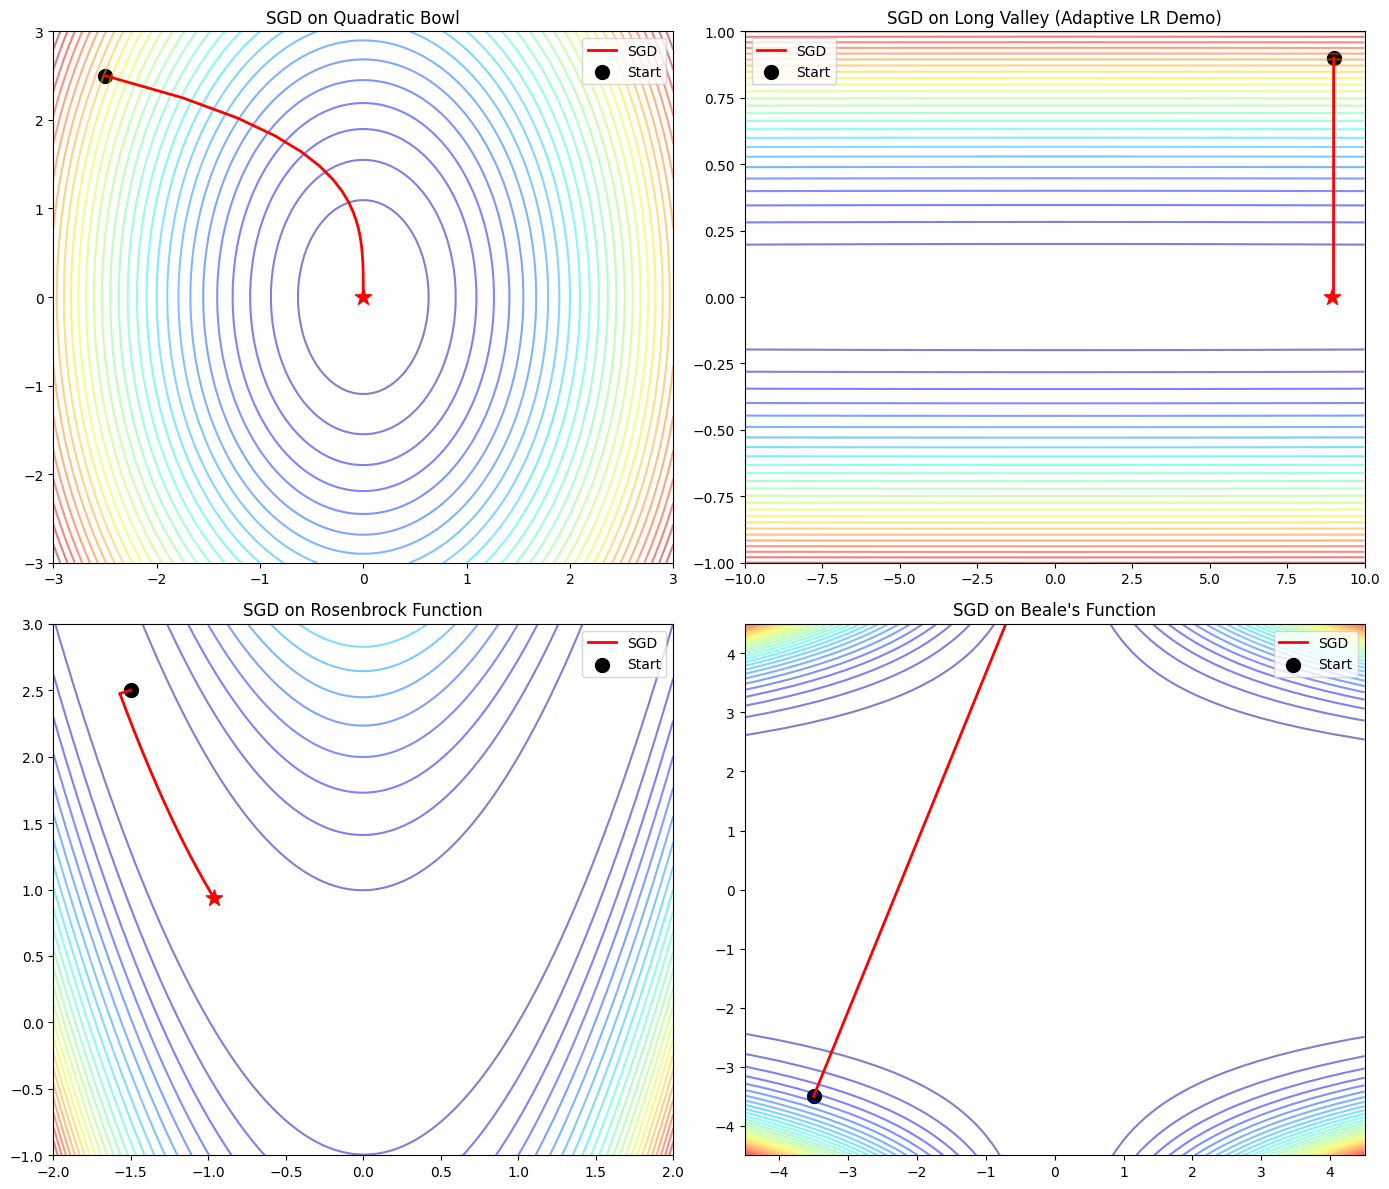

In [181]:
Visualize("SGD" , SGD  )


# Algorithm : SGD with Momentum

Momentum mimics a ball rolling down a hill, adding a fraction of the previous update vector to the current update:
$$v_t = \beta v_{t-1} + \eta \nabla f(\theta_t)$$
$$\theta_{t+1} = \theta_t - v_t$$


In [182]:
def Momentum(fn , fn_grad , pos , lr , epochs) :

    pos = pos.copy()

    b1 = 0.9
    v = 0


    path = [pos ]
    for i in range(epochs) :
      grad = fn_grad(pos[0],pos[1])

      v =  b1*v + grad

      pos = pos - lr*v

      path.append(pos)

    return np.array(path)




/tmp/ipykernel_906/1657754124.py:34: RuntimeWarning: overflow encountered in scalar multiply
  df_dx = 2*(1.5 - x + x*y)*(-1 + y) + 2*(2.25 - x + x*y**2)*(-1 + y**2) + 2*(2.625 - x + x*y**3)*(-1 + y**3)
/tmp/ipykernel_906/1657754124.py:34: RuntimeWarning: overflow encountered in scalar power
  df_dx = 2*(1.5 - x + x*y)*(-1 + y) + 2*(2.25 - x + x*y**2)*(-1 + y**2) + 2*(2.625 - x + x*y**3)*(-1 + y**3)
/tmp/ipykernel_906/1657754124.py:35: RuntimeWarning: overflow encountered in scalar multiply
  df_dy = 2*(1.5 - x + x*y)*(x) + 2*(2.25 - x + x*y**2)*(2*x*y) + 2*(2.625 - x + x*y**3)*(3*x*y**2)
/tmp/ipykernel_906/1657754124.py:35: RuntimeWarning: overflow encountered in scalar power
  df_dy = 2*(1.5 - x + x*y)*(x) + 2*(2.25 - x + x*y**2)*(2*x*y) + 2*(2.625 - x + x*y**3)*(3*x*y**2)
/tmp/ipykernel_906/1657754124.py:34: RuntimeWarning: invalid value encountered in scalar add
  df_dx = 2*(1.5 - x + x*y)*(-1 + y) + 2*(2.25 - x + x*y**2)*(-1 + y**2) + 2*(2.625 - x + x*y**3)*(-1 + y**3)
/tmp/ipyker

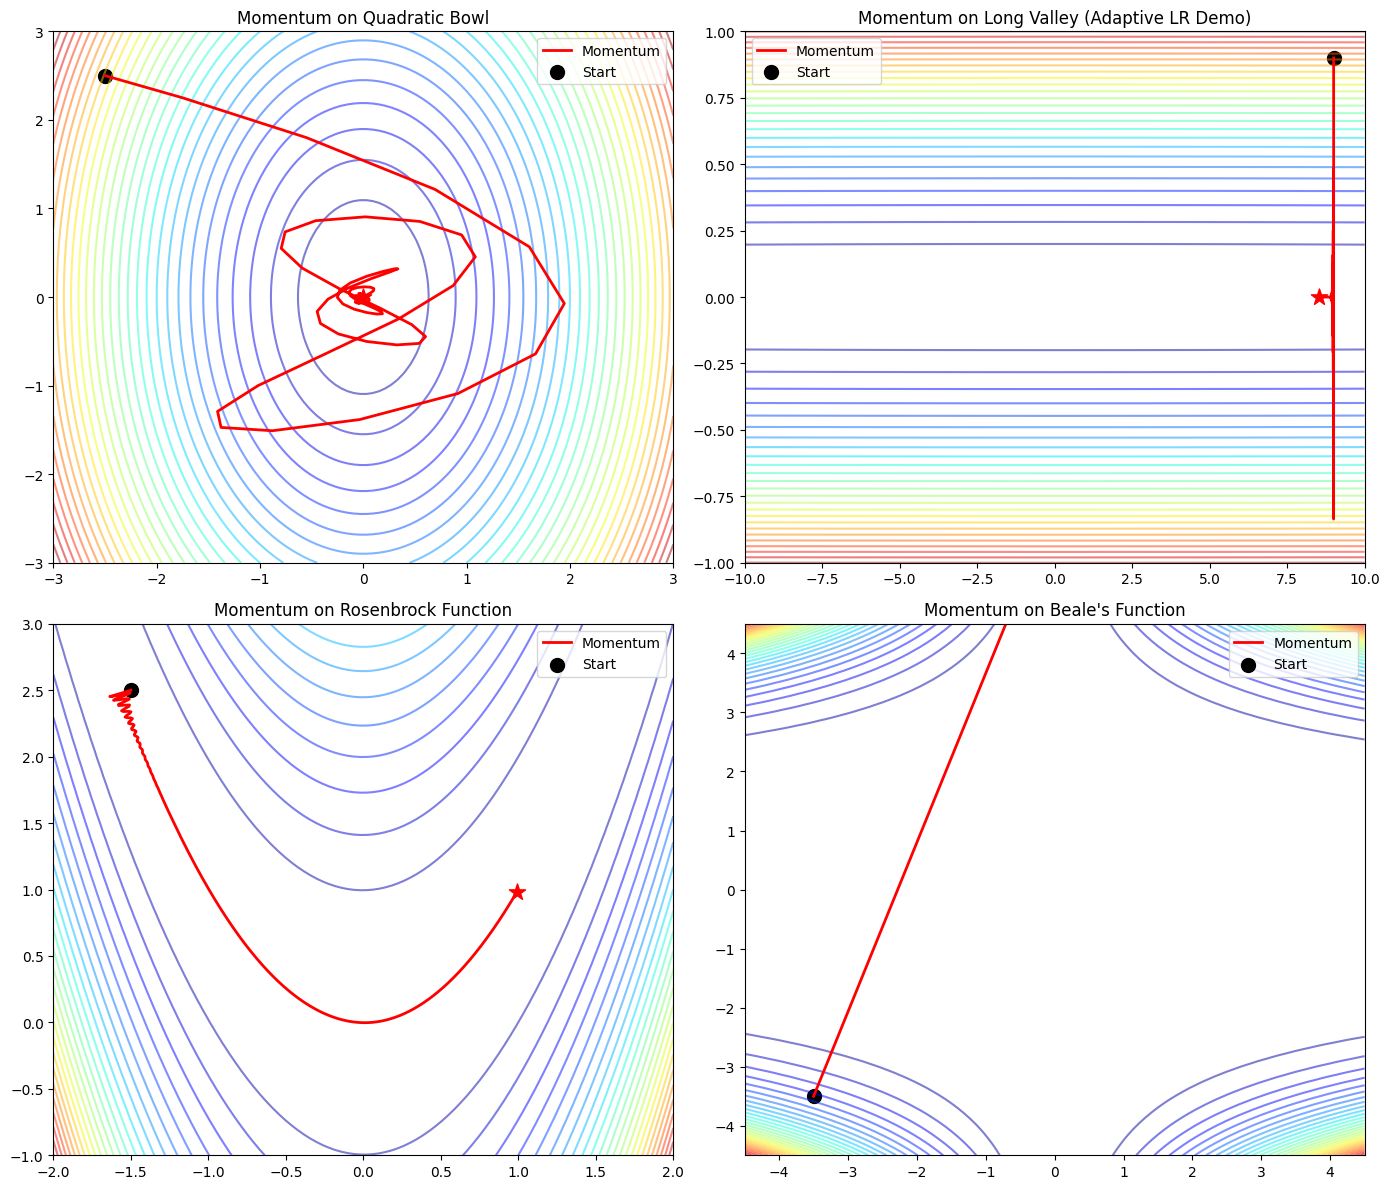

In [183]:
Visualize("Momentum" , Momentum  )

# Algorithm  : Nesterov

/tmp/ipykernel_906/1657754124.py:34: RuntimeWarning: overflow encountered in scalar multiply
  df_dx = 2*(1.5 - x + x*y)*(-1 + y) + 2*(2.25 - x + x*y**2)*(-1 + y**2) + 2*(2.625 - x + x*y**3)*(-1 + y**3)
/tmp/ipykernel_906/1657754124.py:34: RuntimeWarning: overflow encountered in scalar power
  df_dx = 2*(1.5 - x + x*y)*(-1 + y) + 2*(2.25 - x + x*y**2)*(-1 + y**2) + 2*(2.625 - x + x*y**3)*(-1 + y**3)
/tmp/ipykernel_906/1657754124.py:35: RuntimeWarning: overflow encountered in scalar multiply
  df_dy = 2*(1.5 - x + x*y)*(x) + 2*(2.25 - x + x*y**2)*(2*x*y) + 2*(2.625 - x + x*y**3)*(3*x*y**2)
/tmp/ipykernel_906/1657754124.py:35: RuntimeWarning: overflow encountered in scalar power
  df_dy = 2*(1.5 - x + x*y)*(x) + 2*(2.25 - x + x*y**2)*(2*x*y) + 2*(2.625 - x + x*y**3)*(3*x*y**2)
/tmp/ipykernel_906/1657754124.py:34: RuntimeWarning: invalid value encountered in scalar add
  df_dx = 2*(1.5 - x + x*y)*(-1 + y) + 2*(2.25 - x + x*y**2)*(-1 + y**2) + 2*(2.625 - x + x*y**3)*(-1 + y**3)
/tmp/ipyker

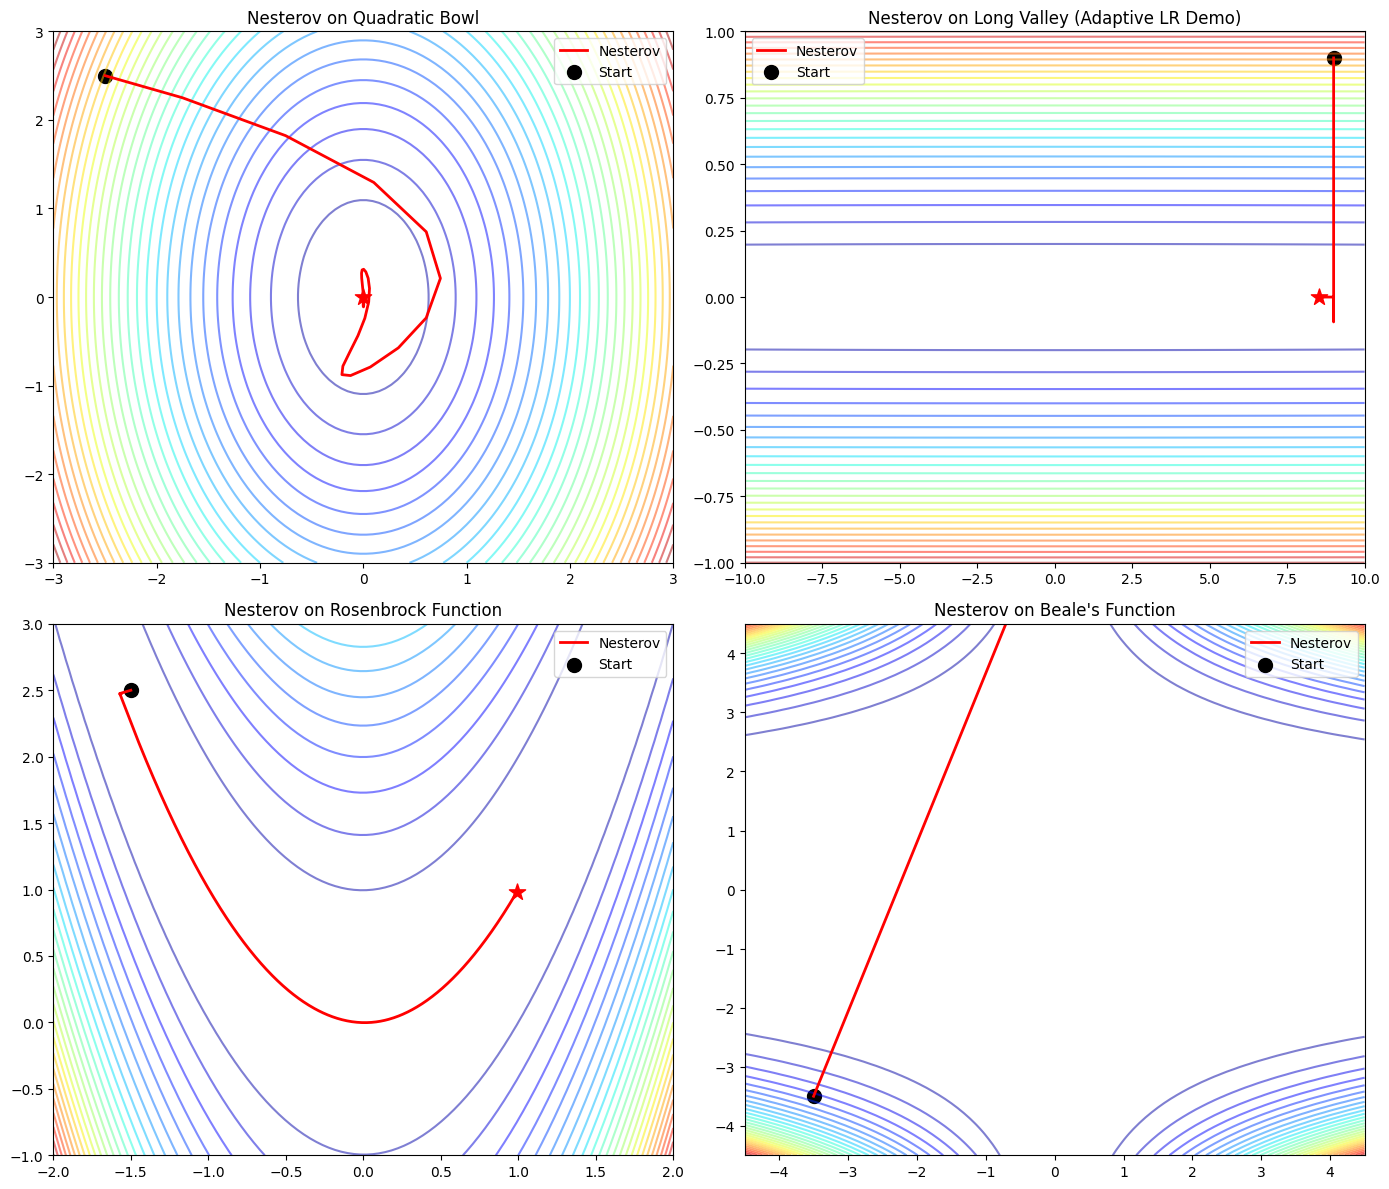

In [198]:


def Nesterov(fn , fn_grad , pos , lr , epochs) :

    pos = pos.copy()

    b1 = 0.9
    v = 0


    path = [pos ]
    for i in range(epochs) :

      look_ahead =  pos - lr*b1*v
      grad = fn_grad(look_ahead[0],look_ahead[1])

      v = b1*v +  grad
      pos = pos - lr*v

      path.append(pos)

    return np.array(path)


Visualize("Nesterov" , Nesterov  )

# Algorithm : Rewritten NAG

In [186]:

def RewrittenNAG(fn , fn_grad , pos , lr , epochs) :

    pos = pos.copy()

    b1 = 0.9
    v = 0


    path = [pos ]
    for i in range(epochs) :

      grad = fn_grad(pos[0],pos[1])

      v = b1*v +  grad
      pos = pos - lr*(b1*v + grad)

      path.append(pos)

    return np.array(path)




/tmp/ipykernel_906/1657754124.py:34: RuntimeWarning: overflow encountered in scalar multiply
  df_dx = 2*(1.5 - x + x*y)*(-1 + y) + 2*(2.25 - x + x*y**2)*(-1 + y**2) + 2*(2.625 - x + x*y**3)*(-1 + y**3)
/tmp/ipykernel_906/1657754124.py:34: RuntimeWarning: overflow encountered in scalar power
  df_dx = 2*(1.5 - x + x*y)*(-1 + y) + 2*(2.25 - x + x*y**2)*(-1 + y**2) + 2*(2.625 - x + x*y**3)*(-1 + y**3)
/tmp/ipykernel_906/1657754124.py:35: RuntimeWarning: overflow encountered in scalar multiply
  df_dy = 2*(1.5 - x + x*y)*(x) + 2*(2.25 - x + x*y**2)*(2*x*y) + 2*(2.625 - x + x*y**3)*(3*x*y**2)
/tmp/ipykernel_906/1657754124.py:35: RuntimeWarning: overflow encountered in scalar power
  df_dy = 2*(1.5 - x + x*y)*(x) + 2*(2.25 - x + x*y**2)*(2*x*y) + 2*(2.625 - x + x*y**3)*(3*x*y**2)
/tmp/ipykernel_906/1657754124.py:34: RuntimeWarning: invalid value encountered in scalar add
  df_dx = 2*(1.5 - x + x*y)*(-1 + y) + 2*(2.25 - x + x*y**2)*(-1 + y**2) + 2*(2.625 - x + x*y**3)*(-1 + y**3)
/tmp/ipyker

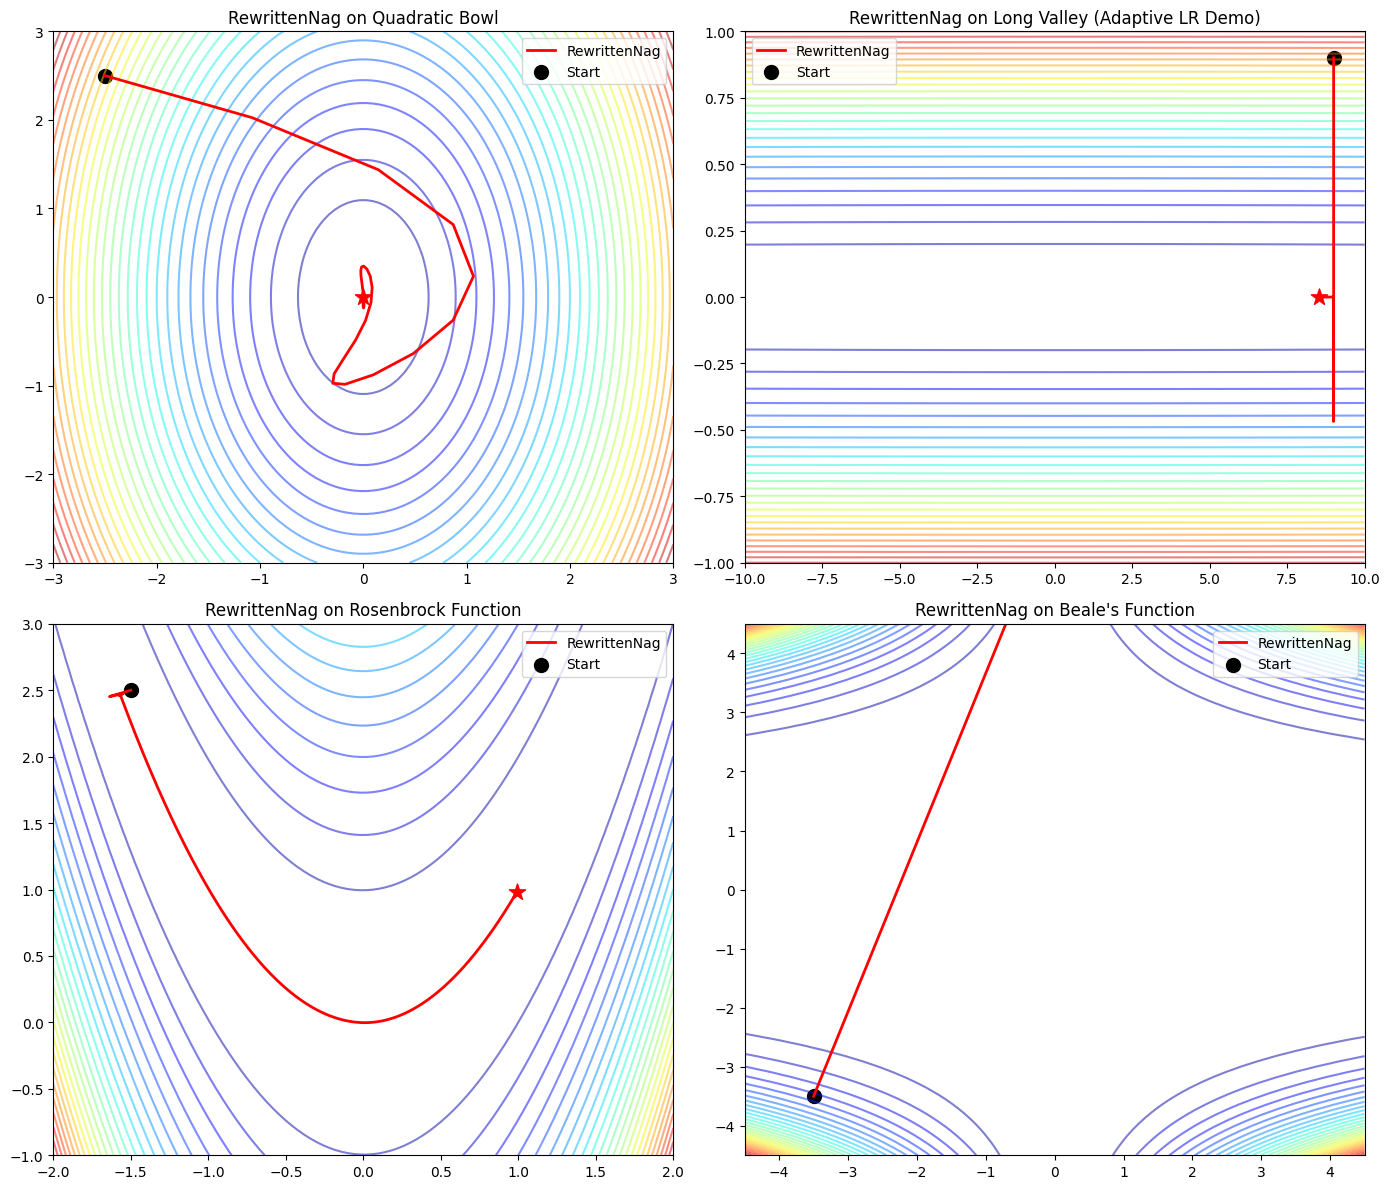

In [187]:
Visualize("RewrittenNag" , RewrittenNAG)

# Algorithm : AdaGrad

In [188]:


def AdaGrad(fn , fn_grad , pos , lr , epochs) :

    pos = pos.copy()
    v = 0
    eps = 1e-8

    path = [pos ]
    for i in range(2*epochs) :
      grad = fn_grad(pos[0],pos[1])

      v =  v + (grad**2)

      pos = pos - lr*grad/(np.sqrt(v) + eps )

      path.append(pos)

    return np.array(path)







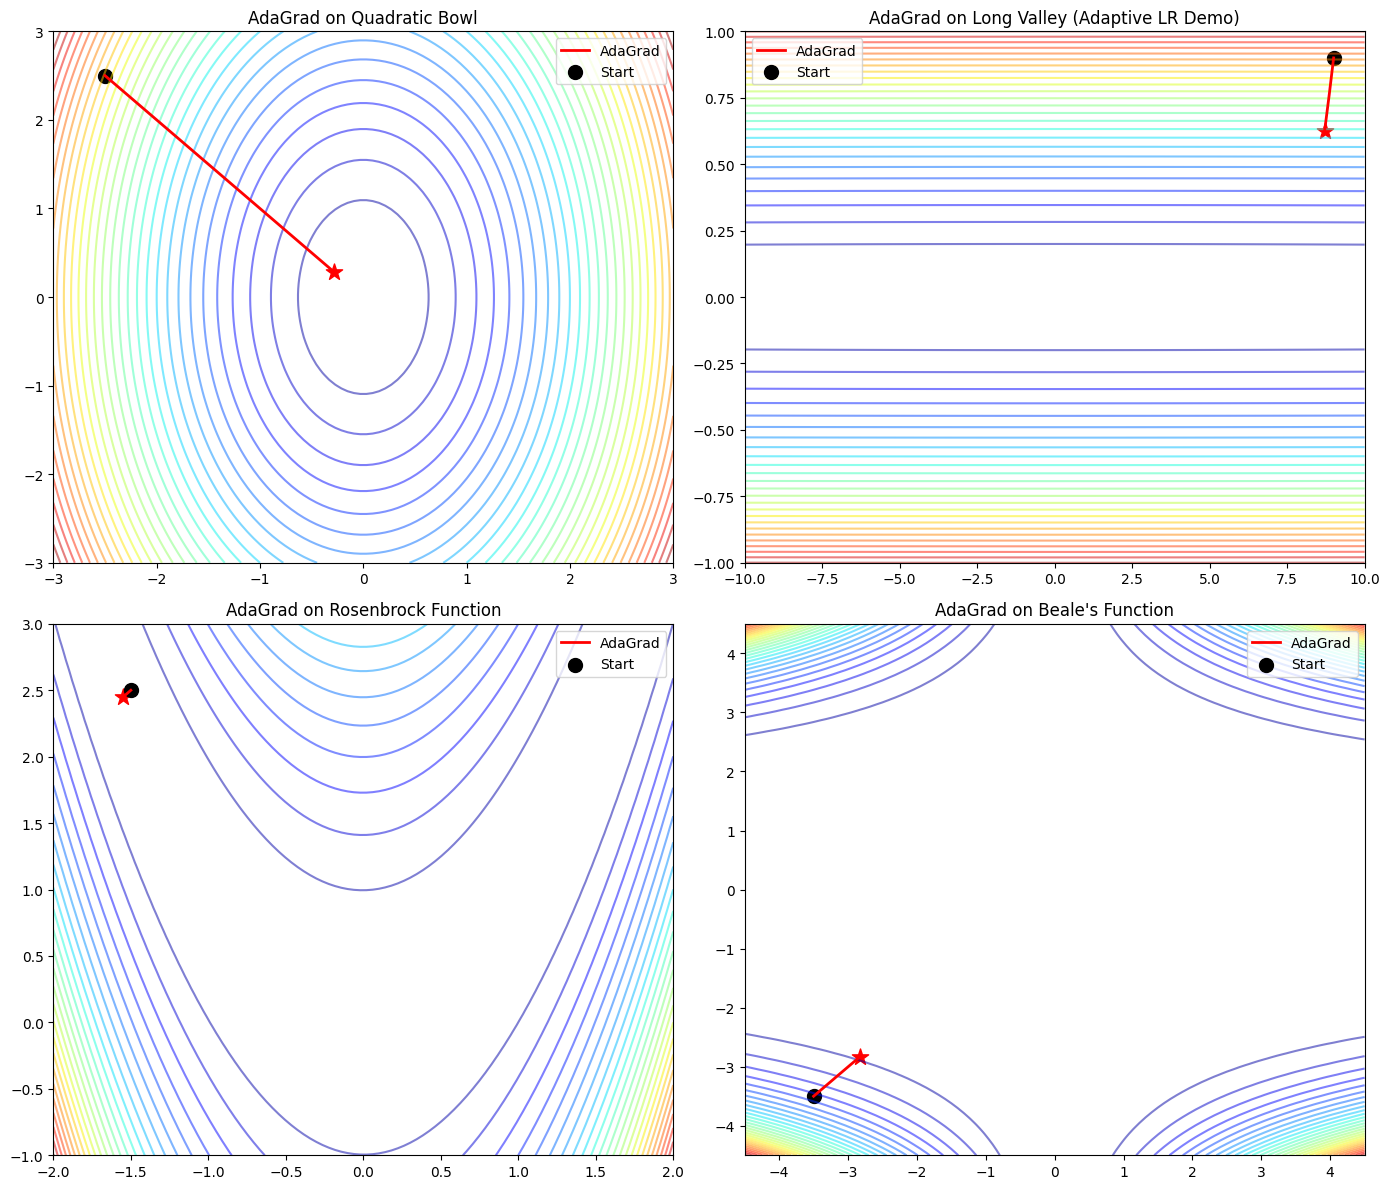

In [189]:
Visualize("AdaGrad" , AdaGrad  )


# Algorithm : RMSprop

RMSprop scales the step size dynamically using an exponentially decaying average of squared gradients:
$$v_t = \beta v_{t-1} + (1-\beta) g_t^2$$
$$\theta_{t+1} = \theta_t - \frac{\eta}{\sqrt{v_t} + \epsilon} g_t$$

In [190]:

def RMSProp(fn , fn_grad , pos , lr , epochs) :

    pos = pos.copy()

    b2 = 0.999
    v = 0
    eps = 1e-8

    path = [pos ]
    for i in range(epochs) :
      grad = fn_grad(pos[0],pos[1])

      v =  b2*v + (1-b2)*(grad**2  )

      pos = pos - lr*grad/(np.sqrt(v) + eps )

      path.append(pos)

    return np.array(path)






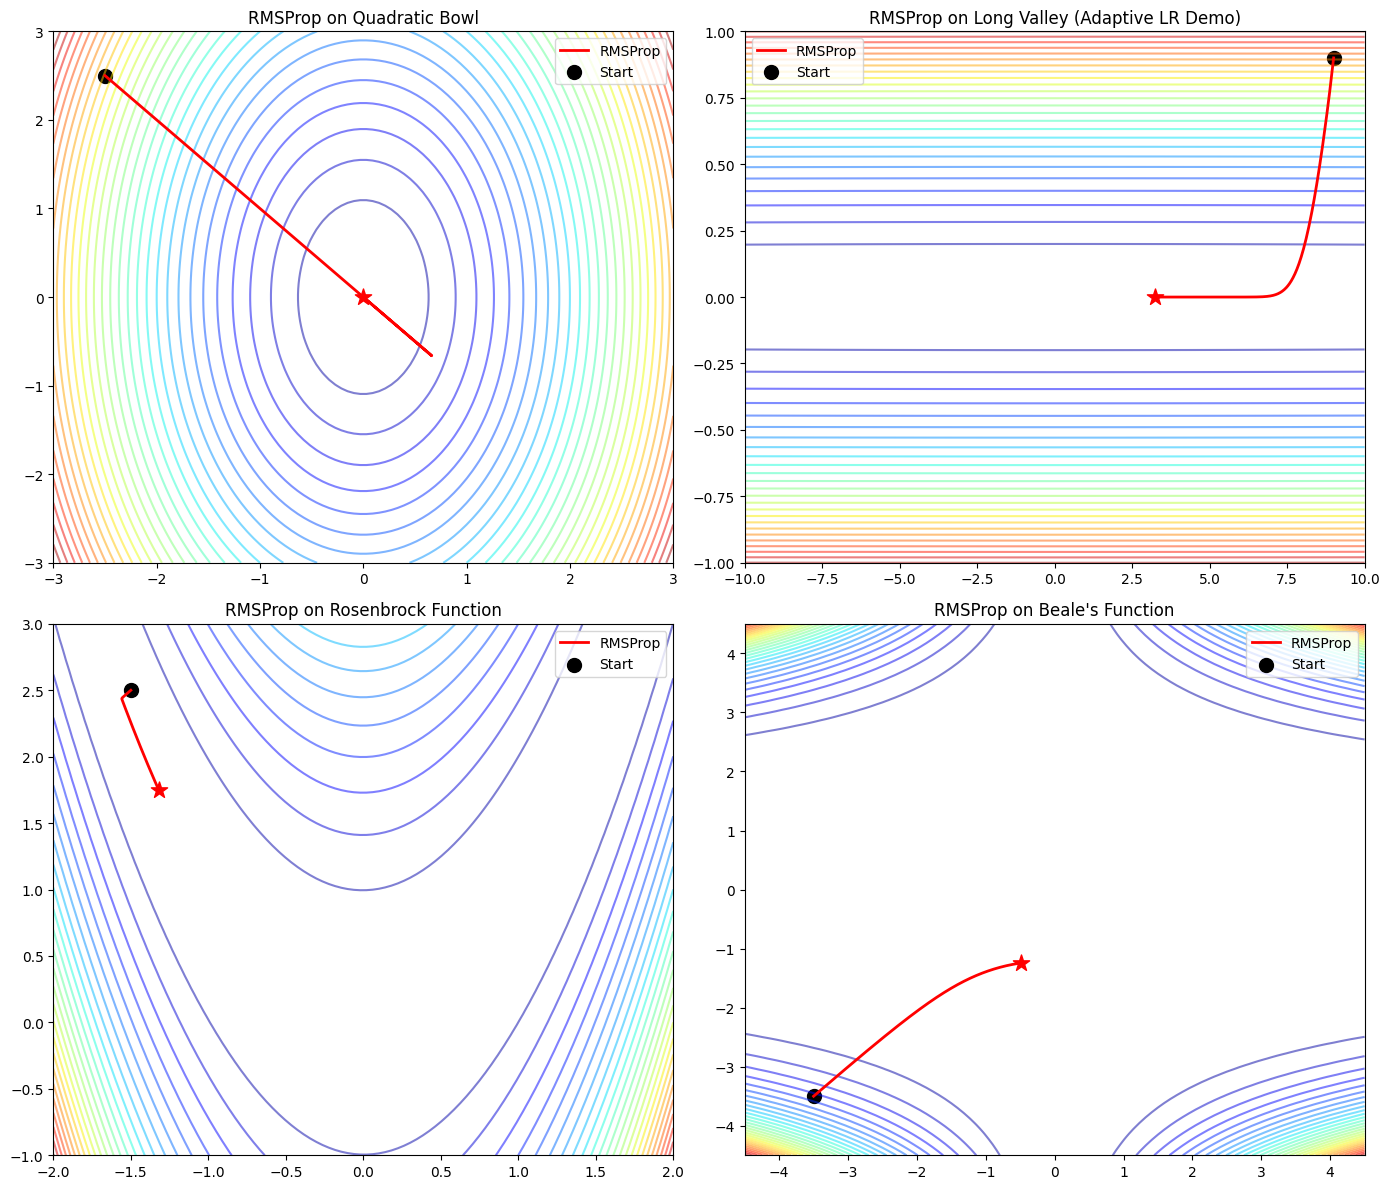

In [191]:

Visualize("RMSProp" , RMSProp  )



# Algorithm : Adam

Adaptive Moment Estimation (Adam) combines Momentum and RMSprop, maintaining estimates of both the first (mean) and second (uncentered variance) moments of the gradient:
$$v_t = \beta_1 v_{t-1} + (1-\beta_1) g_t$$
$$s_t = \beta_2 s_{t-1} + (1-\beta_2) g_t^2$$
$$\hat{v}_t = \frac{v_t}{1-\beta_1^t}, \quad \hat{s}_t = \frac{s_t}{1-\beta_2^t}$$
$$\theta_{t+1} = \theta_t - \frac{\eta}{\sqrt{\hat{s}_t} + \epsilon} \hat{v}_t$$

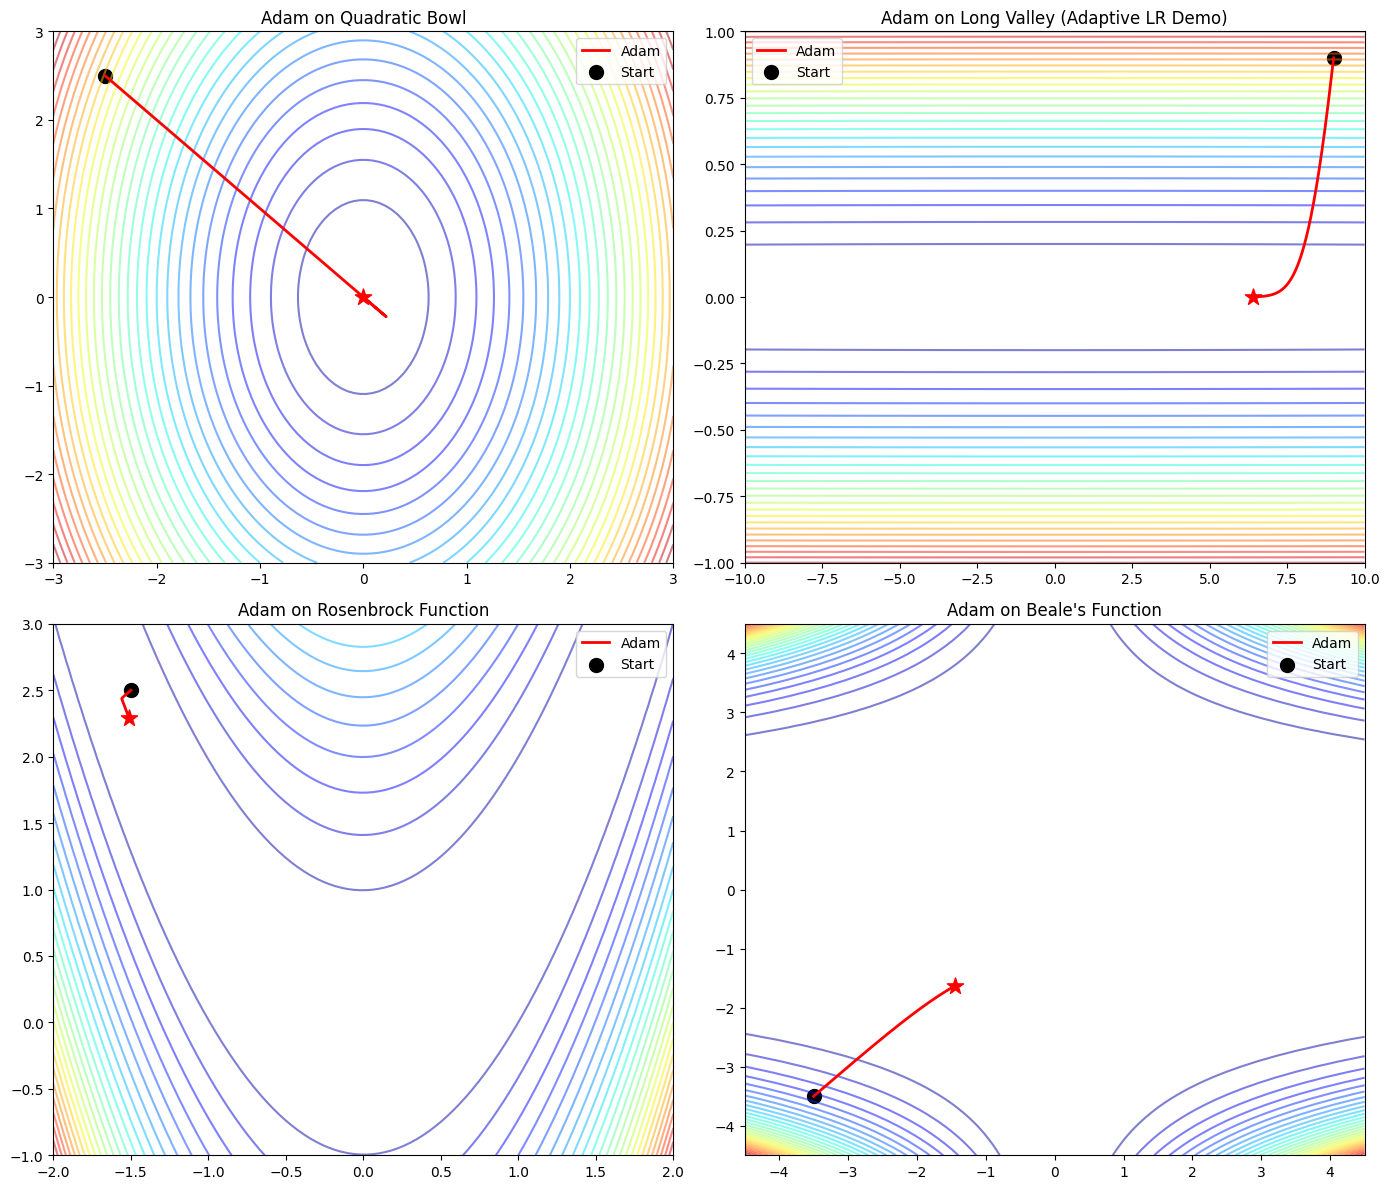

In [192]:
def Adam(fn , fn_grad , pos , lr , epochs) :
    pos = pos.copy()
    b1 = 0.9
    b2 = 0.999
    m = 0
    s = 0
    eps = 1e-8

    path = [pos]
    for i in range(1, epochs + 1):

      grad = fn_grad(pos[0],pos[1])

      m = b1*m + (1-b1)*(grad)

      s = b2*s + (1-b2)*(grad**2)


      ## Bias Correction
      m_hat =  m / (1-(b1**i))
      s_hat = s / (1-(b2**i))

      pos = pos -lr*m_hat / (np.sqrt(s_hat) + eps  )


      path.append(pos)


    return np.array(path)

Visualize("Adam", Adam)